# Global warming levels

Every national projection notebook reports local changes at **global warming levels** (GWLs): the global mean surface temperature rise above 1850–1900. This notebook finds the year at which each SSP scenario first reaches each level and stores the result in `data/projections/warming_levels_ipcc_ar6.pkl`, which the indicator notebooks read.

```{glue:figure} gwl_fig
:scale: 60%
:align: center
```

**Figure. Historical and projected global surface temperature (IPCC AR6 SYR, Figure SPM.4).** Dashed lines mark the warming levels; dots and labels give the year at which each scenario mean crosses them.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from myst_nb import glue

sys.path.append("../../../functions")
import projections as prj

## Data

Global surface temperature change relative to 1850–1900 from the [IPCC AR6 Synthesis Report, Figure SPM.4 panel (a)](https://ipcc-data.climate.columbia.edu/content/ar6-syr-spm4-and-lr-figure-33-linear-graph), stored in `data/projections/ipcc/`.

In [3]:
scenarios = list(prj.SCENARIOS)
warming_levels = list(prj.WARMING_LEVELS)

df_hist, df_proj = prj.read_ipcc_global_temperature()
df_proj.head()

,Year,SSP1_1_9_Mean,SSP1_2_6_5%,SSP1_2_6_Mean,SSP1_2_6_95%,SSP2_4_5_Mean,SSP3_7_0_5%,SSP3_7_0_Mean,SSP3_7_0_95%,SSP5_8_5_Mean
0,2015,1.098807,1.010286,1.099248,1.196469,1.103229,1.004820,1.094355,1.191357,1.110088
1,2016,1.123234,1.027754,1.124936,1.232381,1.126902,1.020226,1.117929,1.223911,1.136830
2,2017,1.148856,1.045768,1.151127,1.267277,1.151919,1.037919,1.143451,1.257962,1.166139
3,2018,1.175205,1.063368,1.176867,1.302330,1.177257,1.055631,1.169831,1.293766,1.195275
4,2019,1.200604,1.081301,1.202266,1.340351,1.202911,1.072719,1.194816,1.333081,1.223858


## Crossing years

In [4]:
scenario_info = prj.warming_level_years(df_proj, scenarios, warming_levels)
path = prj.save_warming_levels(scenario_info)
print(f"Saved {path}")

pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

Saved /Users/laurac/Library/Mobile Documents/com~apple~CloudDocs/Projects/CC_indicators/PICCM/CIndRA/data/projections/warming_levels_ipcc_ar6.pkl


,ssp126,ssp245,ssp370,ssp585
+1.5°C,2032-01-01,2030-01-01,2030-01-01,2027-01-01
+2.0°C,NaT,2052-01-01,2046-01-01,2041-01-01
+2.5°C,NaT,2079-01-01,2061-01-01,2053-01-01
+3.0°C,NaT,NaT,2075-01-01,2064-01-01


## Figure

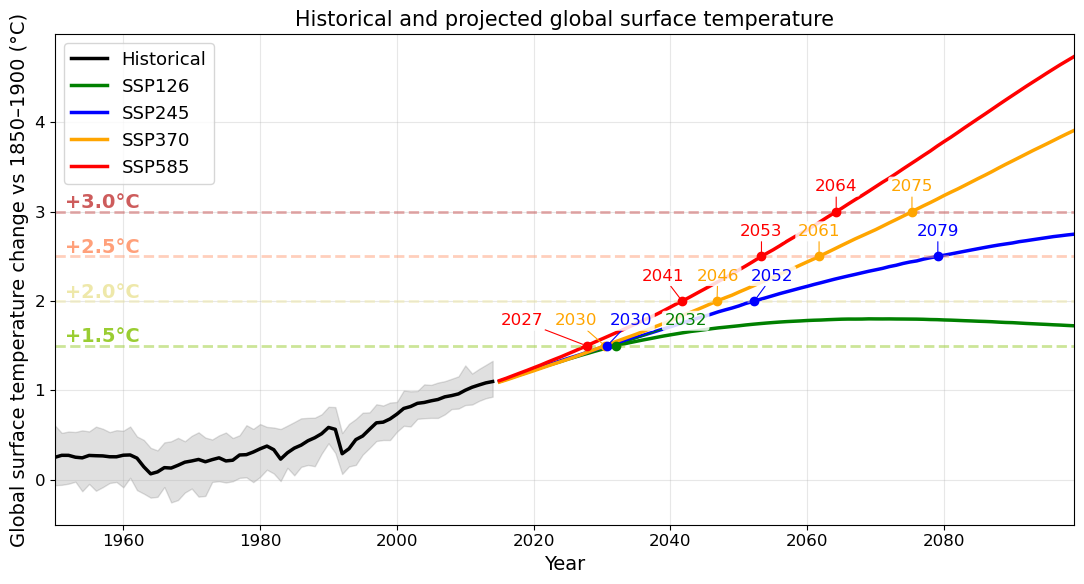

In [5]:
threshold_color = {1.5: "yellowgreen", 2.0: "palegoldenrod", 2.5: "lightsalmon", 3.0: "indianred"}
label_gap = 8.0    # minimum horizontal distance between year labels of the same level (years)
label_rise = 0.28  # height of the labels above their warming level (°C)


def spread_labels(years, gap):
    """Label x-positions at least ``gap`` apart, centred on the crossing years they belong to."""
    xs = list(years)
    for k in range(1, len(xs)):
        xs[k] = max(xs[k], xs[k - 1] + gap)
    shift = np.mean(years) - np.mean(xs) if len(xs) > 1 and np.ptp(years) < gap * (len(xs) - 1) else 0
    return [x + shift for x in xs]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(df_hist["Year"], df_hist["Mean"], color="black", linewidth=2.5, label="Historical")
ax.fill_between(df_hist["Year"], df_hist["0.05"], df_hist["0.95"], color="black", alpha=0.12)

for sc in scenarios:
    ax.plot(df_proj["Year"], df_proj[prj.IPCC_SCENARIO_COLUMNS[sc]], color=prj.SCENARIO_COLOR[sc], linewidth=2.5, label=sc.upper())

for wl in warming_levels:
    ax.axhline(wl, color=threshold_color.get(wl, "grey"), linestyle="--", linewidth=2, alpha=0.5)
    ax.text(0.01, wl + 0.1, f"+{wl:.1f}°C", transform=ax.get_yaxis_transform(), color=threshold_color.get(wl, "grey"),
            fontsize=14, fontweight="bold", ha="left", va="center")
    crossings = sorted((prj.crossing_year(df_proj["Year"], df_proj[prj.IPCC_SCENARIO_COLUMNS[sc]], wl), sc) for sc in scenarios)
    crossings = [(year, sc) for year, sc in crossings if not np.isnan(year)]
    label_x = spread_labels([year for year, _ in crossings], label_gap)
    years = [year for year, _ in crossings]
    for (year, sc), x in zip(crossings, label_x):
        color = prj.SCENARIO_COLOR[sc]
        # scenarios crossing in the same year: draw concentric markers (first = biggest) so all stay visible
        n_same = years.count(year)
        rank = sum(1 for (y, _) in crossings[:crossings.index((year, sc))] if y == year)
        ax.scatter(year, wl, color=color, s=40 + 60 * (n_same - 1 - rank), zorder=5 + rank,
                   edgecolors="white", linewidths=0.8)
        ax.annotate(f"{int(year)}", xy=(year, wl), xytext=(x, wl + label_rise), color=color, fontsize=12,
                    ha="center", va="center", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85),
                    arrowprops=dict(arrowstyle="-", color=color, lw=0.8, shrinkA=0, shrinkB=3))

ax.set_xlim(df_hist["Year"].min(), df_proj["Year"].max())
ax.set(xlabel="Year", ylabel="Global surface temperature change vs 1850–1900 (°C)",
       title="Historical and projected global surface temperature")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

fig_dir = Path("../../../outputs/figures/global")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "PRJ_global_warming_levels_ipcc.png", dpi=150, bbox_inches="tight")
glue("gwl_fig", fig, display=False)

## Crossing years by scenario

Year at which the IPCC AR6 multi-model mean of each scenario first reaches each global warming level (linear interpolation between annual values). "—" means the level is not reached before 2100. The table is also saved to `outputs/tables/global/`.

In [6]:
crossing_table = pd.DataFrame(
    {f"+{wl}°C": [prj.crossing_year(df_proj["Year"], df_proj[prj.IPCC_SCENARIO_COLUMNS[sc]], wl) for sc in scenarios]
     for wl in warming_levels},
    index=pd.Index([sc.upper() for sc in scenarios], name="Scenario"),
).apply(lambda col: col.map(lambda y: "—" if np.isnan(y) else str(int(y))))

table_dir = Path("../../../outputs/tables/global")
table_dir.mkdir(parents=True, exist_ok=True)
crossing_table.to_csv(table_dir / "PRJ_warming_level_crossing_years_ipcc.csv")
crossing_table

,+1.5°C,+2.0°C,+2.5°C,+3.0°C
Scenario,,,,
SSP126,2032,—,—,—
SSP245,2030,2052,2079,—
SSP370,2030,2046,2061,2075
SSP585,2027,2041,2053,2064
